# EfficientNetV2B0 - Replicare Nawaz

**Strict Nawaz:**
- Architecture: EfficientNetV2B0 + Dense(1024) + BN + Dropout + Dense(256) + BN + Dropout + Dense(7)
- Total params: 7,500,375 (match Table 4)
- Loss: sparse_categorical_crossentropy + class_weight (sklearn balanced)
- Optimizer: Adam, LR=1e-3
- Augmentation: flip + rotation +/- 20° + zoom +/- 10%
- Base trainable
- 30 epochs cu EarlyStopping(patience=10) pe val_accuracy
- ReduceLROnPlateau pe val_loss

## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive mounted')

Mounted at /content/drive
Drive mounted


In [ ]:
import os
import json
import time
import random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import ( classification_report, confusion_matrix, roc_auc_score, precision_recall_fscore_support )

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print(f'TF: {tf.__version__}')
print(f'GPU: {tf.config.list_physical_devices("GPU")}')
print(f'Seed: {SEED}')

TF: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Seed: 42


In [ ]:
DRIVE_BASE = Path('/content/drive/MyDrive/Thesis')
PIPELINE_DIR = DRIVE_BASE / 'pipeline_outputs'

TFRECORDS_DIR = PIPELINE_DIR / 'step4_tfrecords'   # val/, test/, tier5/
STEP2_DIR = PIPELINE_DIR / 'step2'                 # tier{N}_train.csv
OUTPUT_DIR = DRIVE_BASE / 'experiments' / 'efficientnetv2b0_naive'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Hyperparameters (strict Nawaz)
IMG_SIZE = 224
NUM_CLASSES = 7
BATCH_SIZE = 32
EPOCHS = 30
LEARNING_RATE = 1e-3
DENSE1_UNITS = 1024
DENSE2_UNITS = 256
DROPOUT_RATE = 0.3
ROTATION_MAX_DEG = 20
ZOOM_RANGE = 0.1

# Paper reference values (din Nawaz Table 4 + Table 5 raportare)
PAPER_TRAINABLE_PARAMS = 7_437_207

TIERS_TO_RUN = [1, 2, 3, 4, 5]
IDX_TO_LABEL = {0: 'akiec', 1: 'bcc', 2: 'bkl', 3: 'df', 4: 'mel', 5: 'nv', 6: 'vasc'}
CLASS_NAMES = [IDX_TO_LABEL[i] for i in range(NUM_CLASSES)]

print(f'TFRecords dir:  {TFRECORDS_DIR.exists()} {TFRECORDS_DIR}')
print(f'Step2 dir:      {STEP2_DIR.exists()} {STEP2_DIR}')
print(f'Output dir:     {OUTPUT_DIR}')
print(f'Tiers to run:   {TIERS_TO_RUN}')

for split in ['val', 'test', 'tier5']:
    d = TFRECORDS_DIR / split
    if d.exists():
        shards = sorted(d.glob('*.tfrecord'))
        print(f'  {split}: {len(shards)} shard-uri')
    else:
        print(f'  [WARNING] {split}/ nu există!')

TFRecords dir:  True /content/drive/MyDrive/Thesis/pipeline_outputs/step4_tfrecords
Step2 dir:      True /content/drive/MyDrive/Thesis/pipeline_outputs/step2
Output dir:     /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive
Tiers to run:   [1, 2, 3, 4, 5]
  val: 3 shard-uri
  test: 3 shard-uri
  tier5: 21 shard-uri


## 2. Data pipeline



In [ ]:
FEATURE_DESC = {
    'image_id':    tf.io.FixedLenFeature([], tf.string),
    'label':       tf.io.FixedLenFeature([], tf.int64),
    'lesion_id':   tf.io.FixedLenFeature([], tf.string),
    'source':      tf.io.FixedLenFeature([], tf.string),
    'image_bytes': tf.io.FixedLenFeature([], tf.string),
}

def parse_example(example_proto):
    return tf.io.parse_single_example(example_proto, FEATURE_DESC)

def decode_image(parsed):
    img = tf.io.decode_jpeg(parsed['image_bytes'], channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0   # [0, 1]
    return img, parsed['label'], parsed['lesion_id']

def get_split_files(split_name):
    pattern = str(TFRECORDS_DIR / split_name / '*.tfrecord')
    files = sorted(tf.io.gfile.glob(pattern))
    if not files:
        raise FileNotFoundError(f'No TFRecords found for split: {split_name}')
    return files

TRAIN_FILES = get_split_files('tier5')
VAL_FILES = get_split_files('val')
TEST_FILES = get_split_files('test')

print(f'Train pool (tier5): {len(TRAIN_FILES)} shards')
print(f'Val:                {len(VAL_FILES)} shards')
print(f'Test:               {len(TEST_FILES)} shards')

Train pool (tier5): 21 shards
Val:                3 shards
Test:               3 shards


In [ ]:
def get_tier_lesion_ids(tier):
    if tier == 5:
        return None
    csv_path = STEP2_DIR / f'tier{tier}_train.csv'
    df = pd.read_csv(csv_path)
    return set(df['lesion_id'].astype(str).tolist())


def make_lesion_filter(allowed_ids):
    keys = tf.constant(sorted(list(allowed_ids)), dtype=tf.string)
    values = tf.ones(len(allowed_ids), dtype=tf.int32)
    table = tf.lookup.StaticHashTable(
        tf.lookup.KeyValueTensorInitializer(keys, values),
        default_value=0,
    )
    return table

for t in TIERS_TO_RUN:
    ids = get_tier_lesion_ids(t)
    if ids is None:
        print(f'Tier {t}: no filter (full tier5)')
    else:
        print(f'Tier {t}: {len(ids):,} lesion_id-uri')

Tier 1: 5,987 lesion_id-uri
Tier 2: 7,276 lesion_id-uri
Tier 3: 8,565 lesion_id-uri
Tier 4: 9,855 lesion_id-uri
Tier 5: no filter (full tier5)


In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal_and_vertical', seed=SEED),
    tf.keras.layers.RandomRotation( factor=ROTATION_MAX_DEG / 360.0, fill_mode='reflect', seed=SEED), # +/-20°
    tf.keras.layers.RandomZoom(
        height_factor=(-ZOOM_RANGE, ZOOM_RANGE),
        width_factor=(-ZOOM_RANGE, ZOOM_RANGE),
        fill_mode='reflect', seed=SEED ),
], name='paper_augmentation')

def preprocess_efficientnet(img_01):
    """Input: float32 [0,1]. Output: float32 [-1,1]."""
    return (img_01 * 255.0) / 127.5 - 1.0

print('Augmentation + preprocessing definite')

Augmentation + preprocessing definite


In [ ]:
def build_train_ds(tier):
    """Train dataset cu .repeat() — filter pe lesion_id pentru tier1-4"""
    allowed_ids = get_tier_lesion_ids(tier)

    ds = tf.data.TFRecordDataset( TRAIN_FILES, num_parallel_reads=tf.data.AUTOTUNE )
    ds = ds.map( parse_example, num_parallel_calls=tf.data.AUTOTUNE )
    ds = ds.map( decode_image, num_parallel_calls=tf.data.AUTOTUNE )

    if allowed_ids is not None:
        table = make_lesion_filter(allowed_ids)
        ds = ds.filter( lambda img, lbl, lid: tf.equal(table.lookup(lid), 1) )

    ds = ds.map( lambda img, lbl, lid: (img, lbl), num_parallel_calls=tf.data.AUTOTUNE )
    ds = ds.repeat()
    ds = ds.shuffle( buffer_size=2000, seed=SEED, reshuffle_each_iteration=True )

    ds = ds.map( lambda img, lbl: (data_augmentation(img, training=True), lbl), num_parallel_calls=tf.data.AUTOTUNE )
    ds = ds.map( lambda img, lbl: (preprocess_efficientnet(img), lbl), num_parallel_calls=tf.data.AUTOTUNE )
    ds = ds.batch( BATCH_SIZE, drop_remainder=True )
    ds = ds.prefetch( tf.data.AUTOTUNE )
    return ds

def build_eval_ds(files):
    """Val/test dataset - fără shuffle, fără repeat, fără augment."""
    ds = tf.data.TFRecordDataset(files, num_parallel_reads=tf.data.AUTOTUNE )
    ds = ds.map( parse_example, num_parallel_calls=tf.data.AUTOTUNE )
    ds = ds.map( decode_image, num_parallel_calls=tf.data.AUTOTUNE )
    ds = ds.map( lambda img, lbl, lid: (img, lbl), num_parallel_calls=tf.data.AUTOTUNE )
    ds = ds.map( lambda img, lbl: (preprocess_efficientnet(img), lbl), num_parallel_calls=tf.data.AUTOTUNE )
    ds = ds.batch( BATCH_SIZE, drop_remainder=False )
    ds = ds.prefetch( tf.data.AUTOTUNE )
    return ds

print('Dataset builders definite')

Dataset builders definite


In [ ]:
def count_tier_samples(tier):
    """Numără sample-uri și calculează distribuția pe clase pentru un tier."""

    allowed_ids = get_tier_lesion_ids(tier)
    ds = tf.data.TFRecordDataset( TRAIN_FILES, num_parallel_reads=tf.data.AUTOTUNE )
    ds = ds.map( parse_example, num_parallel_calls=tf.data.AUTOTUNE )

    if allowed_ids is not None:
        table = make_lesion_filter(allowed_ids)
        ds = ds.filter(lambda x: tf.equal(table.lookup(x['lesion_id']), 1))

    counter = Counter()
    for ex in ds:
        counter[int(ex['label'].numpy())] += 1
    return dict(counter)


TIER_DISTRIBUTIONS = {}
for t in TIERS_TO_RUN:
    dist = count_tier_samples(t)
    TIER_DISTRIBUTIONS[t] = dist
    total = sum(dist.values())
    print(f'  Tier {t}: {total:>6,} samples — {{{", ".join(f"{IDX_TO_LABEL[k]}: {v}" for k, v in sorted(dist.items()))}}}')

val_count = sum(1 for _ in tf.data.TFRecordDataset(VAL_FILES))
test_count = sum(1 for _ in tf.data.TFRecordDataset(TEST_FILES))
print(f'\nVal:  {val_count:,} samples')
print(f'Test: {test_count:,} samples')

Counting samples per tier (asta poate dura ~1-2 min):
  Tier 1:  8,042 samples — {akiec: 268, bcc: 396, bkl: 888, df: 93, mel: 910, nv: 5378, vasc: 109}
  Tier 2: 10,996 samples — {akiec: 502, bcc: 929, bkl: 1177, df: 118, mel: 1600, nv: 6536, vasc: 134}
  Tier 3: 14,061 samples — {akiec: 720, bcc: 1495, bkl: 1504, df: 138, mel: 2296, nv: 7750, vasc: 158}
  Tier 4: 17,300 samples — {akiec: 946, bcc: 2077, bkl: 1836, df: 164, mel: 3062, nv: 9022, vasc: 193}
  Tier 5: 20,299 samples — {akiec: 1192, bcc: 2661, bkl: 2128, df: 184, mel: 3628, nv: 10297, vasc: 209}

Val:  2,519 samples
Test: 2,513 samples


In [ ]:
def compute_class_weights(distribution):
    """sklearn 'balanced': total / (n_classes * count_per_class)."""
    total = sum(distribution.values())
    return {k: total / (NUM_CLASSES * v) for k, v in distribution.items()}


TIER_CLASS_WEIGHTS = {}
print('Class weights per tier:')
for t in TIERS_TO_RUN:
    cw = compute_class_weights(TIER_DISTRIBUTIONS[t])
    TIER_CLASS_WEIGHTS[t] = cw
    cw_str = ', '.join(f'{IDX_TO_LABEL[k]}: {v:.2f}' for k, v in sorted(cw.items()))
    print(f'  Tier {t}: {cw_str}')

Class weights per tier:
  Tier 1: akiec: 4.29, bcc: 2.90, bkl: 1.29, df: 12.35, mel: 1.26, nv: 0.21, vasc: 10.54
  Tier 2: akiec: 3.13, bcc: 1.69, bkl: 1.33, df: 13.31, mel: 0.98, nv: 0.24, vasc: 11.72
  Tier 3: akiec: 2.79, bcc: 1.34, bkl: 1.34, df: 14.56, mel: 0.87, nv: 0.26, vasc: 12.71
  Tier 4: akiec: 2.61, bcc: 1.19, bkl: 1.35, df: 15.07, mel: 0.81, nv: 0.27, vasc: 12.81
  Tier 5: akiec: 2.43, bcc: 1.09, bkl: 1.36, df: 15.76, mel: 0.80, nv: 0.28, vasc: 13.87


## 3. Model (strict Nawaz Table 4)

Architecture:
```
Input(224, 224, 3)
  -> EfficientNetV2B0 (5,919,312)
  -> GlobalAveragePooling2D
  -> Dense(1024, relu) (1,311,744)
  -> BatchNormalization (4,096)
  -> Dropout(0.3)
  -> Dense(256, relu) (262,400)
  -> BatchNormalization (1,024)
  -> Dropout(0.3)
  -> Dense(7, softmax) (1,799)
  
Total: 7,500,375
Trainable: 7,437,207
```

In [ ]:
def build_efficientnetv2b0():

    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    base = tf.keras.applications.EfficientNetV2B0( include_top=False, weights='imagenet', input_shape=(IMG_SIZE, IMG_SIZE, 3) )
    base.trainable = True
    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)

    x = tf.keras.layers.Dense(DENSE1_UNITS, activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(DROPOUT_RATE)(x)

    x = tf.keras.layers.Dense(DENSE2_UNITS, activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(DROPOUT_RATE)(x)

    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    model = tf.keras.Model(inputs, outputs, name='EfficientNetV2B0')

    total = model.count_params()
    trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
    print(f'  Total params:     {total:>12,}')
    print(f'  Trainable params: {trainable:>12,}')
    print(f'  Paper trainable:  {PAPER_TRAINABLE_PARAMS:>12,}')
    match = abs(trainable - PAPER_TRAINABLE_PARAMS) < 1000
    print(f'  Match Nawaz: {"YES" if match else "NO"}')

    return model

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
  Total params:        7,500,375
  Trainable params:    7,437,207
  Paper trainable:     7,437,207
  Match Nawaz: YES ✓


## 4. Training utilities

In [ ]:
def get_callbacks(tier_dir):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(tier_dir / 'best.keras'),
            monitor='val_accuracy', mode='max',
            save_best_only=True, verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy', mode='max',
            patience=10, restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5,
            patience=3, min_lr=1e-7, verbose=1
        ),
        tf.keras.callbacks.CSVLogger(
            filename=str(tier_dir / 'history.csv'), append=False
        ),
    ]


print('Callbacks definite')

Callbacks definite


In [ ]:
def evaluate_model(model, ds, label='test'):
    """Evaluate cu accuracy, precision, recall, F1, AUC, confusion matrix."""

    print(f'Evaluating on {label}...')
    y_true, y_pred, y_proba = [], [], []
    for imgs, labels in ds:
        preds = model.predict(imgs, verbose=0)
        y_proba.extend(preds)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_proba = np.array(y_proba)

    acc = float(np.mean(y_true == y_pred))
    prec, rec, f1, _ = precision_recall_fscore_support( y_true, y_pred, average='weighted', zero_division=0 )
    macro_f1 = precision_recall_fscore_support( y_true, y_pred, average='macro', zero_division=0 )[2]
    try:
        auc = float(roc_auc_score(y_true, y_proba, multi_class='ovr', average='weighted'))
    except Exception:
        auc = float('nan')

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    report = classification_report( y_true, y_pred, target_names=CLASS_NAMES, zero_division=0 )

    print(f'  Accuracy:    {acc*100:.2f}%')
    print(f'  Precision:   {prec:.4f}')
    print(f'  Recall:      {rec:.4f}')
    print(f'  Weighted F1: {f1:.4f}')
    print(f'  Macro F1:    {macro_f1:.4f}')
    print(f'  AUC (ovr):   {auc:.4f}')

    return {
        'accuracy': acc,
        'precision': float(prec),
        'recall': float(rec),
        'weighted_f1': float(f1),
        'macro_f1': float(macro_f1),
        'auc': auc,
        'confusion_matrix': cm.tolist(),
        'classification_report': report,
    }

In [ ]:
def plot_results(history, cm, tier, save_path):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    axes[0].plot(history.history['accuracy'], label='Train')
    axes[0].plot(history.history['val_accuracy'], label='Val')
    axes[0].set_title(f'Tier {tier} — Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history.history['loss'], label='Train')
    axes[1].plot(history.history['val_loss'], label='Val')
    axes[1].set_title(f'Tier {tier} — Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    sns.heatmap( cm, annot=True, fmt='d', cmap='Blues', ax=axes[2], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False )
    axes[2].set_title(f'Tier {tier} — Confusion Matrix (test)')
    axes[2].set_xlabel('Predicted')
    axes[2].set_ylabel('True')

    plt.tight_layout()
    plt.savefig(save_path, dpi=120, bbox_inches='tight')
    plt.show()

In [ ]:
def train_tier(tier):

    tier_dir = OUTPUT_DIR / f'tier{tier}'
    tier_dir.mkdir(parents=True, exist_ok=True)

    results_path = tier_dir / 'results.json'
    if results_path.exists():
        print(f'\n   Tier {tier} already done, loading...')
        with open(results_path) as f:
            return json.load(f)

    print(f'\n{"#"*70}')
    print(f'# TIER {tier}')
    print(f'#   Output: {tier_dir}')
    print(f'#   Train samples: {sum(TIER_DISTRIBUTIONS[tier].values()):,}')
    print(f'#   LR={LEARNING_RATE}, batch={BATCH_SIZE}, epochs={EPOCHS}')
    print(f'{"#"*70}')

    start = time.time()

    tf.random.set_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)

    train_ds = build_train_ds(tier)
    val_ds = build_eval_ds(VAL_FILES)
    test_ds = build_eval_ds(TEST_FILES)

    train_samples = sum(TIER_DISTRIBUTIONS[tier].values())
    steps_per_epoch = max(1, (train_samples // BATCH_SIZE) - 1)
    print(f'  Steps per epoch: {steps_per_epoch}')

    model = build_efficientnetv2b0()
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='sparse_categorical_crossentropy', metrics=['accuracy']
    )

    history = model.fit(
        train_ds,
        epochs=EPOCHS,
        steps_per_epoch=steps_per_epoch,
        validation_data=val_ds,
        class_weight=TIER_CLASS_WEIGHTS[tier],
        callbacks=get_callbacks(tier_dir),
        verbose=1,
    )

    val_metrics = evaluate_model(model, val_ds, label=f'tier{tier}_val')
    test_metrics = evaluate_model(model, test_ds, label=f'tier{tier}_test')
    plot_results( history, np.array(test_metrics['confusion_matrix']), tier, save_path=tier_dir / 'plots.png' )
    elapsed_min = (time.time() - start) / 60

    results = {
        'tier': tier,
        'train_samples': train_samples,
        'epochs_run': len(history.history['loss']),
        'time_minutes': elapsed_min,
        'val': val_metrics,
        'test': test_metrics,
        'history': {k: [float(x) for x in v] for k, v in history.history.items()},
    }


    with open(results_path, 'w') as f:
        json.dump(results, f, indent=2, default=str)
    model.save(tier_dir / 'final.keras')

    print(f'\n  Tier {tier} done in {elapsed_min:.1f} min')
    print(f'  Test accuracy: {test_metrics["accuracy"]*100:.2f}%')

    del model, train_ds, val_ds, test_ds
    tf.keras.backend.clear_session()
    import gc
    gc.collect()

    return results

## 5. Run all tiers


######################################################################
# TIER 1
#   Output: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier1
#   Train samples: 8,042
#   LR=0.001, batch=32, epochs=30
######################################################################
  Steps per epoch: 250
  Total params:        7,500,375
  Trainable params:    7,437,207
  Paper trainable:     7,437,207
  Match Nawaz: YES ✓
Epoch 1/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.2700 - loss: 2.0775
Epoch 1: val_accuracy improved from None to 0.03493, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier1/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier1/best.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 146s 164ms/step - accuracy: 0.3255 - loss: 1.8255 - val_accuracy: 0.0349 - val_loss: 2.1987 - learning_rate: 0.0010
Epoch 2/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.4544 - loss: 1.3623
Epoch 2: val_accuracy improved from 0.03493 to 0.13220, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier1/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier1/best.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 81ms/step - accuracy: 0.4652 - loss: 1.3382 - val_accuracy: 0.1322 - val_loss: 2.2593 - learning_rate: 0.0010
Epoch 3/30
249/250 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.5173 - loss: 1.1292
Epoch 3: val_accuracy did not improve from 0.13220
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 80ms/step - accuracy: 0.5254 - loss: 1.1772 - val_accuracy: 0.0091

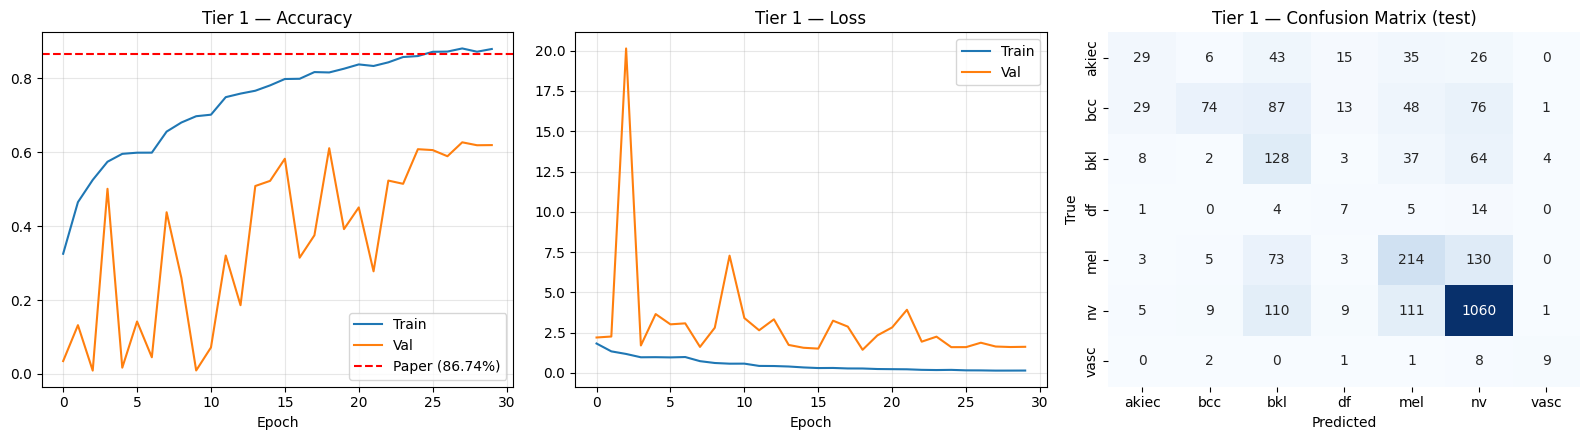


✓ Tier 1 done in 12.5 min
  Test accuracy: 60.53%
  Paper:         86.74%

######################################################################
# TIER 2
#   Output: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier2
#   Train samples: 10,996
#   LR=0.001, batch=32, epochs=30
######################################################################
  Steps per epoch: 342
  Total params:        7,500,375
  Trainable params:    7,437,207
  Paper trainable:     7,437,207
  Match Nawaz: YES ✓
Epoch 1/30
341/342 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.2901 - loss: 1.9936
Epoch 1: val_accuracy improved from None to 0.05320, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier2/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier2/best.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 116s 101ms/step - accuracy: 0.3417 - loss: 1.8012 - val_accuracy: 0.0532 - val_loss: 2.4495 - learning_rate: 0.0010
Epoch 2/30
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.4671 - loss: 1.2859
Epoch 2: val_accuracy improved from 0.05320 to 0.49464, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier2/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier2/best.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 25s 72ms/step - accuracy: 0.4721 - loss: 1.3979 - val_accuracy: 0.4946 - val_loss: 1.8627 - learning_rate: 0.0010
Epoch 3/30
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.5142 - loss: 1.2149
Epoch 3: val_accuracy did not improve from 0.49464
342/342 ━━━━━━━━━━━━━━━━━━━━ 25s 73ms/step - accuracy: 0.4994 - loss: 1.2524 - val_accuracy: 0.0107

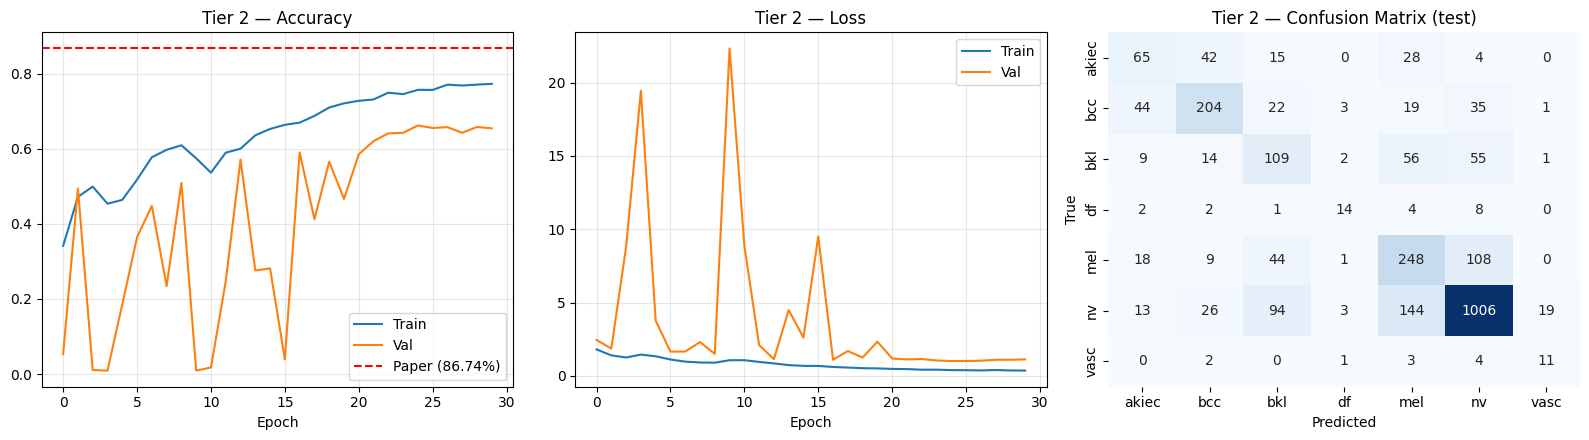


✓ Tier 2 done in 14.8 min
  Test accuracy: 65.94%
  Paper:         86.74%

######################################################################
# TIER 3
#   Output: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier3
#   Train samples: 14,061
#   LR=0.001, batch=32, epochs=30
######################################################################
  Steps per epoch: 438
  Total params:        7,500,375
  Trainable params:    7,437,207
  Paper trainable:     7,437,207
  Match Nawaz: YES ✓
Epoch 1/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.3183 - loss: 1.7610
Epoch 1: val_accuracy improved from None to 0.04684, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier3/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier3/best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 122s 93ms/step - accuracy: 0.3527 - loss: 1.7294 - val_accuracy: 0.0468 - val_loss: 2.2570 - learning_rate: 0.0010
Epoch 2/30
437/438 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.4201 - loss: 1.3863
Epoch 2: val_accuracy did not improve from 0.04684
438/438 ━━━━━━━━━━━━━━━━━━━━ 29s 66ms/step - accuracy: 0.4336 - loss: 1.4493 - val_accuracy: 0.0183 - val_loss: 3.2502 - learning_rate: 0.0010
Epoch 3/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.4184 - loss: 1.3888
Epoch 3: val_accuracy improved from 0.04684 to 0.22430, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier3/best.keras

Epoch 3: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier3/best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 30s 69ms/step - accuracy: 0.4443 - loss: 1.3585 - val_accuracy: 0.2243 

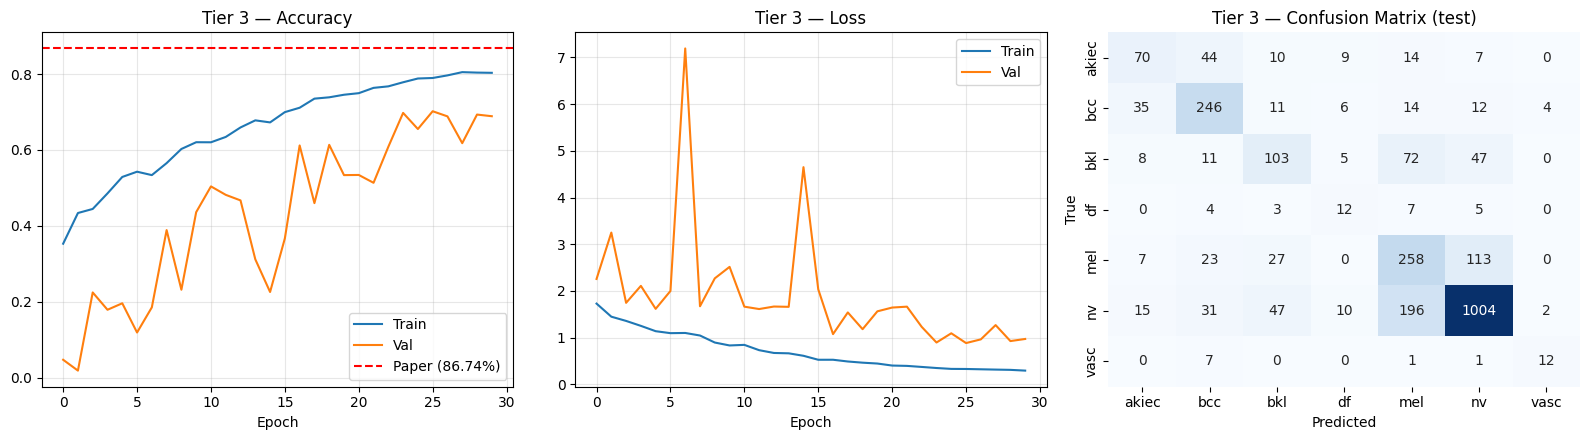


✓ Tier 3 done in 17.7 min
  Test accuracy: 67.85%
  Paper:         86.74%

######################################################################
# TIER 4
#   Output: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier4
#   Train samples: 17,300
#   LR=0.001, batch=32, epochs=30
######################################################################
  Steps per epoch: 539
  Total params:        7,500,375
  Trainable params:    7,437,207
  Paper trainable:     7,437,207
  Match Nawaz: YES ✓
Epoch 1/30
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.3321 - loss: 1.7551
Epoch 1: val_accuracy improved from None to 0.00913, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier4/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier4/best.keras
539/539 ━━━━━━━━━━━━━━━━━━━━ 129s 87ms/step - accuracy: 0.3850 - loss: 1.6436 - val_accuracy: 0.0091 - val_loss: 2.5269 - learning_rate: 0.0010
Epoch 2/30
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.4696 - loss: 1.3115
Epoch 2: val_accuracy did not improve from 0.00913
539/539 ━━━━━━━━━━━━━━━━━━━━ 35s 64ms/step - accuracy: 0.4676 - loss: 1.4006 - val_accuracy: 0.0091 - val_loss: 7.7857 - learning_rate: 0.0010
Epoch 3/30
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.4600 - loss: 1.4187
Epoch 3: val_accuracy improved from 0.00913 to 0.50536, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier4/best.keras

Epoch 3: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier4/best.keras
539/539 ━━━━━━━━━━━━━━━━━━━━ 36s 67ms/step - accuracy: 0.4115 - loss: 1.6023 - val_accuracy: 0.5054 

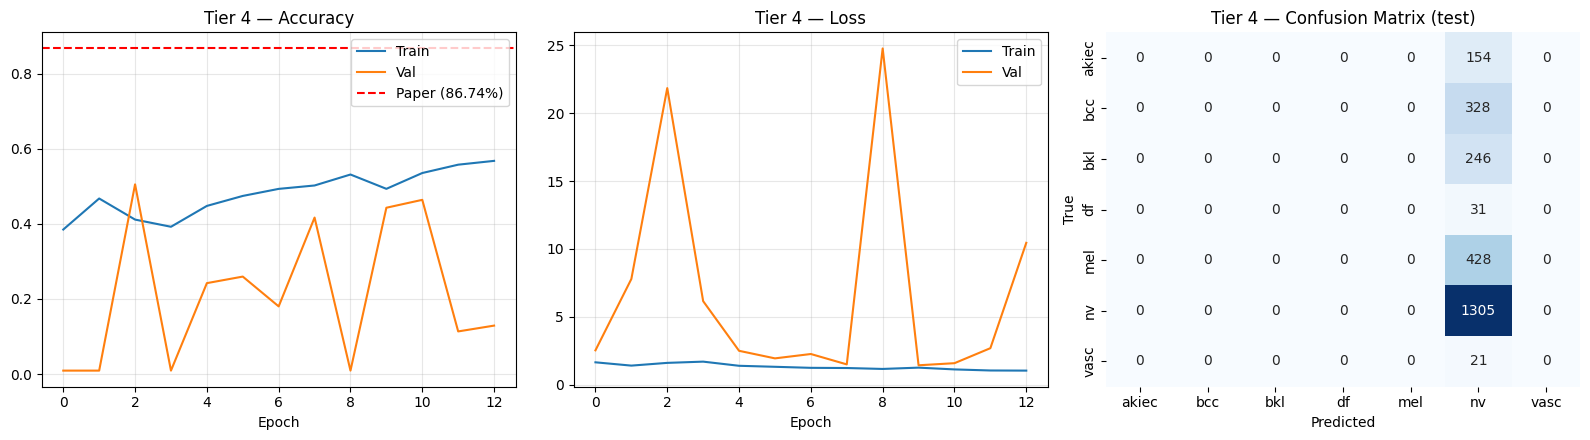


✓ Tier 4 done in 9.8 min
  Test accuracy: 51.93%
  Paper:         86.74%

######################################################################
# TIER 5
#   Output: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier5
#   Train samples: 20,299
#   LR=0.001, batch=32, epochs=30
######################################################################
  Steps per epoch: 633
  Total params:        7,500,375
  Trainable params:    7,437,207
  Paper trainable:     7,437,207
  Match Nawaz: YES ✓
Epoch 1/30
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.3612 - loss: 1.7624
Epoch 1: val_accuracy improved from None to 0.05200, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier5/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier5/best.keras
633/633 ━━━━━━━━━━━━━━━━━━━━ 132s 83ms/step - accuracy: 0.3879 - loss: 1.7215 - val_accuracy: 0.0520 - val_loss: 2.5000 - learning_rate: 0.0010
Epoch 2/30
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.3556 - loss: 1.4839
Epoch 2: val_accuracy did not improve from 0.05200
633/633 ━━━━━━━━━━━━━━━━━━━━ 40s 63ms/step - accuracy: 0.4091 - loss: 1.4994 - val_accuracy: 0.0091 - val_loss: 34.1096 - learning_rate: 0.0010
Epoch 3/30
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.4924 - loss: 1.1324
Epoch 3: val_accuracy improved from 0.05200 to 0.50814, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier5/best.keras

Epoch 3: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/tier5/best.keras
633/633 ━━━━━━━━━━━━━━━━━━━━ 41s 65ms/step - accuracy: 0.5030 - loss: 1.2372 - val_accuracy: 0.5081

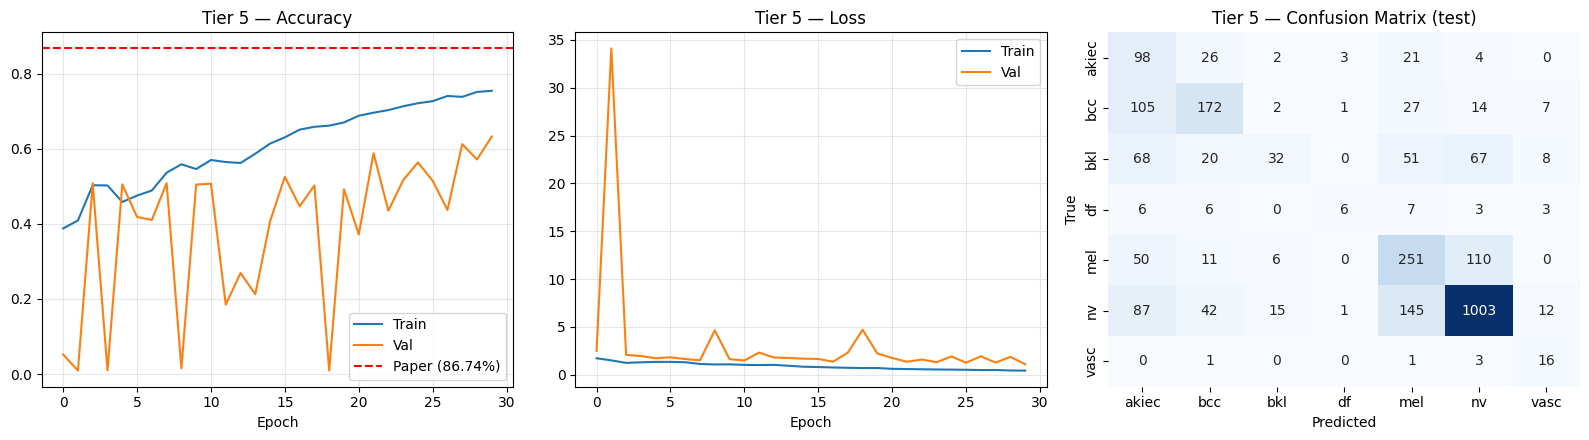


✓ Tier 5 done in 23.6 min
  Test accuracy: 62.79%
  Paper:         86.74%

ALL TIERS COMPLETE


In [ ]:
all_results = {}
for tier in TIERS_TO_RUN:
    all_results[tier] = train_tier(tier)

print('\n' + '=' * 70)
print('ALL TIERS COMPLETE')
print('=' * 70)

## 6. Summary

In [ ]:
rows = []
for tier, res in sorted(all_results.items()):
    rows.append({
        'tier': tier,
        'train_samples': res['train_samples'],
        'epochs': res['epochs_run'],
        'val_acc': res['val']['accuracy'] * 100,
        'val_macro_f1': res['val']['macro_f1'],
        'test_acc': res['test']['accuracy'] * 100,
        'test_macro_f1': res['test']['macro_f1'],
        'test_weighted_f1': res['test']['weighted_f1'],
        'test_auc': res['test']['auc'],
        'time_min': res['time_minutes'],
    })

summary_df = pd.DataFrame(rows)
print(summary_df.to_string(index=False, float_format=lambda x: f'{x:.3f}'))

summary_df.to_csv(OUTPUT_DIR / 'summary.csv', index=False)
print(f'\nSummary saved to: {OUTPUT_DIR / "summary.csv"}')

 tier  train_samples  epochs  val_acc  val_macro_f1  test_acc  test_macro_f1  test_weighted_f1  test_auc  paper_acc  gap_to_paper  time_min
    1           8042      30   62.723         0.496    60.525          0.417             0.597     0.826     86.740        26.215    12.485
    2          10996      30   66.217         0.551    65.937          0.535             0.666     0.873     86.740        20.803    14.771
    3          14061      30   70.187         0.606    67.847          0.561             0.683     0.889     86.740        18.893    17.685
    4          17300      13   50.536         0.096    51.930          0.098             0.355     0.571     86.740        34.810     9.753
    5          20299      30   63.279         0.483    62.793          0.461             0.630     0.869     86.740        23.947    23.583

Summary saved to: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0_naive/summary.csv


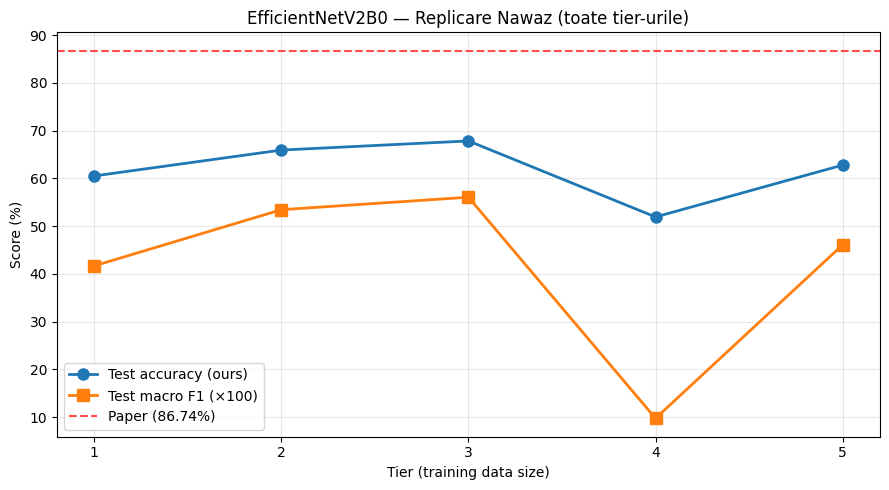

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

tiers_x = [r['tier'] for r in rows]
test_acc = [r['test_acc'] for r in rows]
macro_f1 = [r['test_macro_f1'] * 100 for r in rows]

ax.plot(tiers_x, test_acc, 'o-', label='Test accuracy (ours)', linewidth=2, markersize=8)
ax.plot(tiers_x, macro_f1, 's-', label='Test macro F1 (×100)', linewidth=2, markersize=8)
ax.set_xlabel('Tier (training data size)')
ax.set_ylabel('Score (%)')
ax.set_title('EfficientNetV2B0 — Replicare Nawaz (toate tier-urile)')
ax.set_xticks(tiers_x)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'tiers_summary.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
for tier in sorted(all_results.keys()):
    print(f'\n{"="*70}\nTier {tier} — TEST classification report\n{"="*70}')
    print(all_results[tier]['test']['classification_report'])


Tier 1 — TEST classification report
              precision    recall  f1-score   support

       akiec       0.39      0.19      0.25       154
         bcc       0.76      0.23      0.35       328
         bkl       0.29      0.52      0.37       246
          df       0.14      0.23      0.17        31
         mel       0.47      0.50      0.49       428
          nv       0.77      0.81      0.79      1305
        vasc       0.60      0.43      0.50        21

    accuracy                           0.61      2513
   macro avg       0.49      0.41      0.42      2513
weighted avg       0.64      0.61      0.60      2513


Tier 2 — TEST classification report
              precision    recall  f1-score   support

       akiec       0.43      0.42      0.43       154
         bcc       0.68      0.62      0.65       328
         bkl       0.38      0.44      0.41       246
          df       0.58      0.45      0.51        31
         mel       0.49      0.58      0.53       428
    